In [45]:
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from rdkit import Chem
from rdkit.Chem import rdmolops
import numpy as np


In [53]:
def smiles_to_graph(smiles):

    non_metal_atoms = ['H', 'He', 'C', 'N', 'O', 'F', 'Ne', 'P', 'S', 
                       'Cl', 'Ar', 'Se', 'Br', 'Kr', 'I', 'Xe', 'At', 'Rn']
    halogen_atoms = ['F', 'Cl', 'Br', 'I', 'At', 'Ts']
    
    # one-hot encoding of atom type
    atom_types = ['C', 'N', 'O', 'F', 'S', 'Cl', 'Br', 'P', 'I']
    hybrids = ['SP2','SP3']

    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError("Invalid SMILES string")

    # Extract node features (atom types)
    node_features = []
    for atom in mol.GetAtoms():
        atom_type = atom.GetSymbol()
        hybrid = str(atom.GetHybridization()).upper()

        # one-hot encoding of atom type and hybridization
        atom_type = [float(atom_type == x) for x in atom_types]
        hybrid = [float(hybrid == x) for x in hybrids]

        feature = [atom.GetMass(),
                   atom.GetDegree(),
                   atom.GetTotalNumHs(),
                   float(atom.IsInRing()),
                   float(atom.GetIsAromatic()),
                   float(not atom.GetSymbol() in non_metal_atoms),
                   float(atom.GetSymbol() in halogen_atoms),
                   float(atom.GetFormalCharge() >=0),
                   float(atom.GetFormalCharge() < 0)
                   ]
        feature.extend(atom_type)
        feature.extend(hybrid)
        node_features.append(feature)  
        print(f'\n==={atom.GetSymbol()}===')
        print(feature)
        print(len(feature))
        print(node_features)
    
    node_features = torch.tensor(node_features, dtype=torch.float32)

    # Extract edge indices
    edge_indices = []
    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()
        edge_indices.append([i, j])
        edge_indices.append([j, i])
    edge_indices = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

    return Data(x=node_features, edge_index=edge_indices)


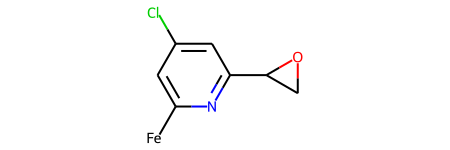

In [48]:
#smiles = 'CCO' 
smiles = 'C(=CC(=CC1C(O2)C2)[Cl])(N=1)[Fe]'
mol = Chem.MolFromSmiles(smiles)
mol


===C===
[12.011, 3, 0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
20
[[12.011, 3, 0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0]]

===C===
[12.011, 2, 1, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
20
[[12.011, 3, 0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0], [12.011, 2, 1, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0]]

===C===
[12.011, 3, 0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
20
[[12.011, 3, 0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0], [12.011, 2, 1, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0], [12.011, 3, 0, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0]]

===C===
[12.011, 2, 1, 1.0, 1.0, 0.0, 0.0, 1.0, 0.0, 1

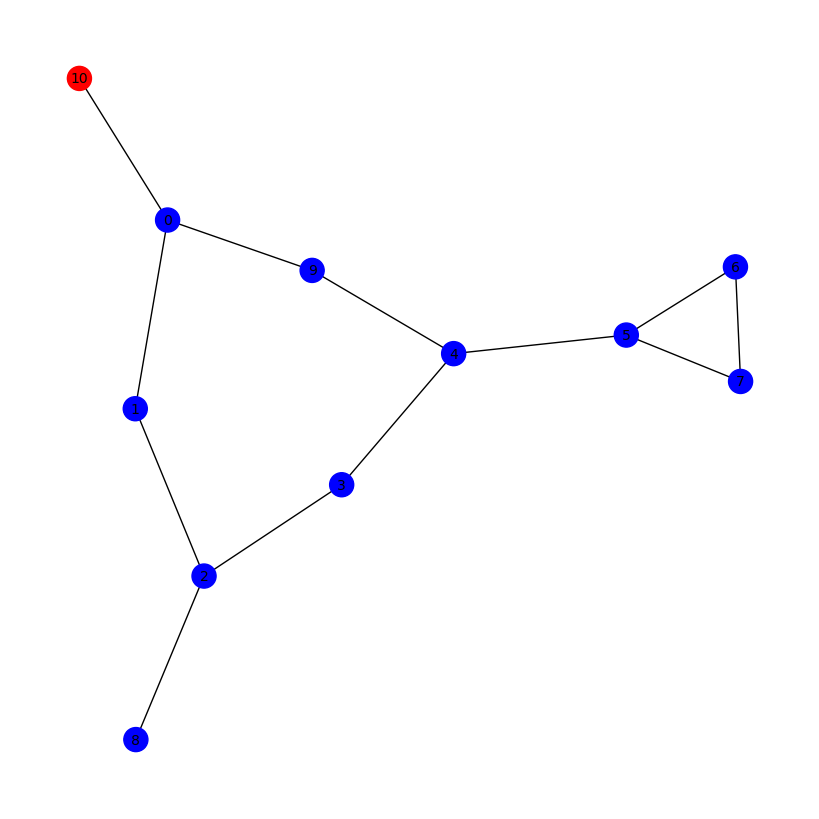

In [54]:
graph_data = smiles_to_graph(smiles)
print(graph_data)
# draw the graph
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
G.add_nodes_from(range(graph_data.x.size(0)))
G.add_edges_from(graph_data.edge_index.t().numpy())

# color nodes according to whether node_feature[5] is 1 or 0 (metal or non-metal)
color_map = []
for i in range(graph_data.x.size(0)):
    if graph_data.x[i][5] == 1:
        color_map.append('red')
    else:
        color_map.append('blue')

plt.figure(figsize=(8, 8))
nx.draw(G, with_labels=True, node_color=color_map, node_size=300, font_size=10)

plt.show()

In [43]:
dataset = [smiles_to_graph(smiles) for smiles in ['CCO', 'CCN', 'CCC']]
torch.save(dataset, './test.pt')

/var/folders/np/zrpshs6j7_19xthy_nj6l4q40000gn/T/ipykernel_69820/2246822743.py:42: DeprecationWarning: an integer is required (got type float).  Implicit conversion to integers using __int__ is deprecated, and may be removed in a future version of Python.
  node_features = torch.tensor(node_features, dtype=torch.long)


OSError: [Errno 30] Read-only file system: './test.pt'